In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import sqlite3
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report


In [3]:
connection=sqlite3.connect('../ecommerce.db')

customers=pd.read_csv(
    '../data/olist_customers_dataset.csv', 
    encoding='latin1')

orders=pd.read_csv(
    '../data/olist_orders_dataset.csv',
    encoding='latin1'

)

order_items=pd.read_csv(
    '../data/olist_order_items_dataset.csv',
    encoding='latin1'
)
pyamets=pd.read_csv(
    '../data/olist_order_payments_dataset.csv',
    encoding='latin1'
)
#print(customers.head())
#print(orders.head())

#print(customers.shape)
#print(orders.shape)

print(customers.columns)
print(orders.columns)

#print(customers.dtypes)
#print(orders.dtypes)

#print(customers.isna().sum())
#print(orders.isna().sum())

print(customers['customer_id'].nunique())
print(customers['customer_unique_id'].nunique())
print(orders['order_id'].nunique())

or_cus=pd.merge(
    customers, 
    orders, 
    on='customer_id', 
    how= 'outer')

orders_per_customer=(or_cus.groupby(
    'customer_unique_id')
    ['order_id'].count()
)

repeat_customers=orders_per_customer[orders_per_customer>1]
print(repeat_customers.count())

df=pd.read_sql_query("""

with tab1 as (SELECT c.customer_unique_id, count(DISTINCT o.order_id) as orders_count,
       SUM(oi.price + oi.freight_value) AS total_spent
FROM order_items AS oi
JOIN orders AS o 
    ON o.order_id = oi.order_id
JOIN customers AS c 
    ON c.customer_id = o.customer_id
GROUP BY c.customer_unique_id),

tab3 as (
    select max(order_purchase_timestamp)
    as last_order_date
    from orders
),

tab4 as (select customer_unique_id, 
    MAX(order_purchase_timestamp) 
    as last_order_date,
    MIN(order_purchase_timestamp) 
    as first_order_date
from customers as c
join orders as o 
    on o.customer_id=c.customer_id
GROUP by customer_unique_id),

feature_table as (
select tab1.customer_unique_id,
        tab1.total_spent,
        tab1.orders_count,
        tab1.total_spent/tab1.orders_count as avg_order_value,
        ROUND(
           julianday(tab3.last_order_date) 
           - julianday(tab4.last_order_date)
       ) AS days_since_last_order,

        round(
        julianday(tab4.last_order_date) 
        - julianday(tab4.first_order_date)
        )AS customer_lifetime_days,
        case when ROUND(
           julianday(tab3.last_order_date) 
           - julianday(tab4.last_order_date)
       )>90 then 1
       else 0
       end as churn
from tab1
join tab4 
    on tab1.customer_unique_id=tab4.customer_unique_id 
cross join tab3)
select* from feature_table;

""", connection)
connection.close()

Index(['customer_id', 'customer_unique_id', 'customer_zip_code_prefix',
       'customer_city', 'customer_state'],
      dtype='str')
Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date'],
      dtype='str')
99441
96096
99441
2997


In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 95420 entries, 0 to 95419
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_unique_id      95420 non-null  str    
 1   total_spent             95420 non-null  float64
 2   orders_count            95420 non-null  int64  
 3   avg_order_value         95420 non-null  float64
 4   days_since_last_order   95420 non-null  float64
 5   customer_lifetime_days  95420 non-null  float64
 6   churn                   95420 non-null  int64  
dtypes: float64(4), int64(2), str(1)
memory usage: 5.1 MB


In [ ]:
df.head()

,customer_unique_id,total_spent,orders_count,avg_order_value,days_since_last_order,customer_lifetime_days,churn
0,0000366f3b9a7992bf8c76cfdf3221e2,141.90,1,141.90,160.0,0.0,1
1,0000b849f77a49e4a4ce2b2a4ca5be3f,27.19,1,27.19,163.0,0.0,1
2,0000f46a3911fa3c0805444483337064,86.22,1,86.22,586.0,0.0,1
3,0000f6ccb0745a6a4b88665a16c9f078,43.62,1,43.62,370.0,0.0,1
4,0004aac84e0df4da2b147fca70cf8255,196.89,1,196.89,337.0,0.0,1


In [ ]:
df.isna().sum()

customer_unique_id        0
total_spent               0
orders_count              0
avg_order_value           0
days_since_last_order     0
customer_lifetime_days    0
churn                     0
dtype: int64

In [ ]:
df.describe()

,total_spent,orders_count,avg_order_value,days_since_last_order,customer_lifetime_days,churn
count,95420.000000,95420.000000,95420.000000,95420.000000,95420.000000,95420.000000
mean,166.040172,1.034018,161.044770,287.517952,2.741543,0.900325
std,228.320333,0.211234,221.191784,153.164470,25.535843,0.299568
min,9.590000,1.000000,9.590000,1.000000,0.000000,0.000000
25%,63.100000,1.000000,62.410000,163.000000,0.000000,1.000000
50%,107.940000,1.000000,105.770000,268.000000,0.000000,1.000000
75%,183.220000,1.000000,177.122500,397.000000,0.000000,1.000000
max,13664.080000,16.000000,13664.080000,773.000000,633.000000,1.000000


In [ ]:
df.shape

(95420, 7)

In [ ]:
df.dtypes

customer_unique_id            str
total_spent               float64
orders_count                int64
avg_order_value           float64
days_since_last_order     float64
customer_lifetime_days    float64
churn                       int64
dtype: object

In [ ]:
df['churn'].value_counts(normalize=True)*100

churn
1    90.032488
0     9.967512
Name: proportion, dtype: float64

In [ ]:
df.groupby('churn')['orders_count'].mean()

churn
0    1.038797
1    1.033489
Name: orders_count, dtype: float64

In [ ]:
df.groupby('churn')['total_spent'].mean()

churn
0    165.001342
1    166.155181
Name: total_spent, dtype: float64

In [ ]:
df.groupby('churn')['customer_lifetime_days'].mean()

churn
0    5.484071
1    2.437917
Name: customer_lifetime_days, dtype: float64

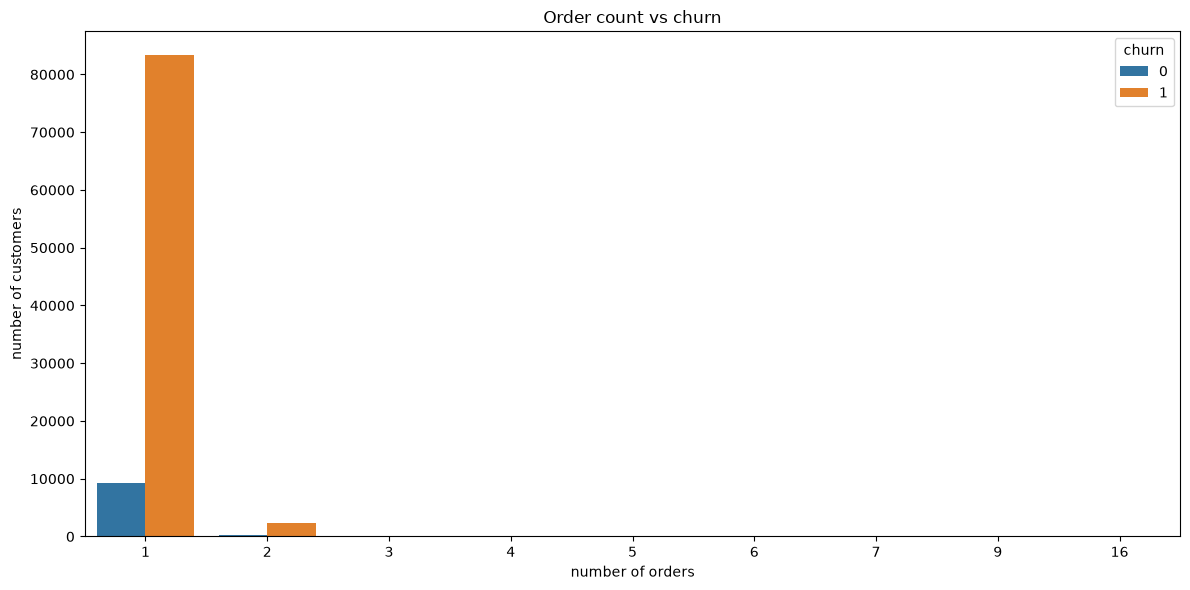

In [ ]:
plt.figure(figsize=(12,6))
sns.countplot(
    data=df, 
    x='orders_count', 
    hue='churn'
)
plt.title('Order count vs churn')
plt.tight_layout()
plt.xlabel('number of orders')
plt.ylabel('number of customers')


In [ ]:
df.groupby('churn')['avg_order_value'].mean()

churn
0    159.278619
1    161.240301
Name: avg_order_value, dtype: float64

In [ ]:
df.groupby('churn')['customer_lifetime_days'].mean()

churn
0    5.484071
1    2.437917
Name: customer_lifetime_days, dtype: float64

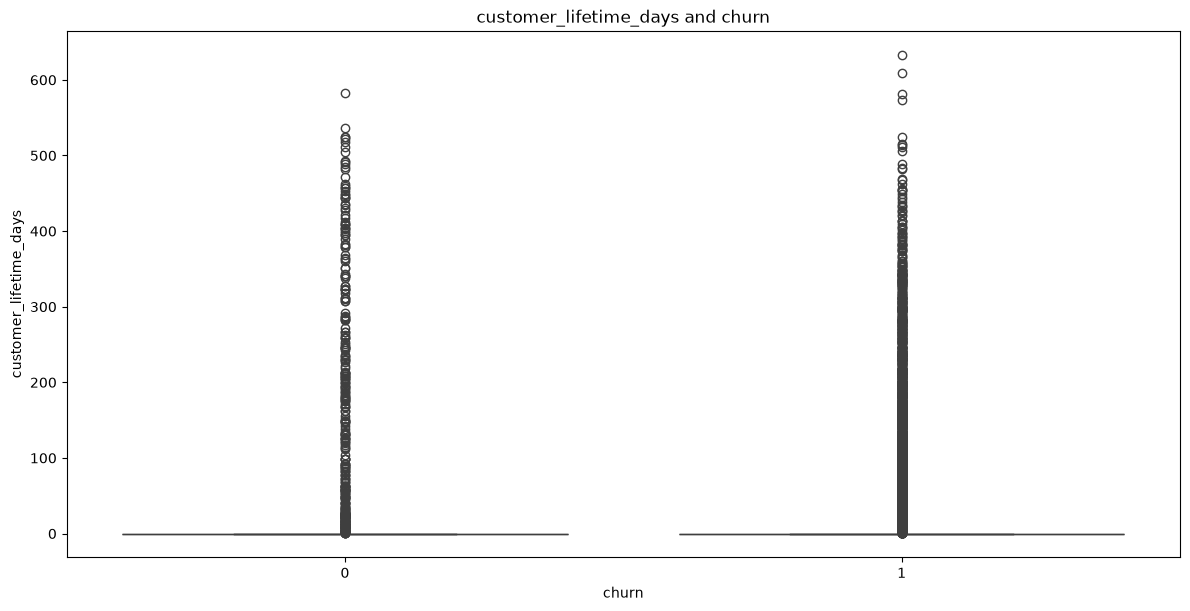

In [ ]:
plt.figure(figsize=(12,6))
sns.boxplot(
    data=df,
    x='churn',
    y='customer_lifetime_days'
)
plt.tight_layout()
plt.title('customer_lifetime_days and churn')
plt.xlabel('churn')
plt.ylabel('customer_lifetime_days')
plt.show()


In [ ]:
data_data=df[['orders_count',
         'total_spent',
         'avg_order_value',
         'customer_lifetime_days'
]]
print(data_data)


       orders_count  total_spent  avg_order_value  customer_lifetime_days
0                 1       141.90           141.90                     0.0
1                 1        27.19            27.19                     0.0
2                 1        86.22            86.22                     0.0
3                 1        43.62            43.62                     0.0
4                 1       196.89           196.89                     0.0
...             ...          ...              ...                     ...
95415             1      2067.42          2067.42                     0.0
95416             1        84.58            84.58                     0.0
95417             1       112.46           112.46                     0.0
95418             1       133.69           133.69                     0.0
95419             1        71.56            71.56                     0.0

[95420 rows x 4 columns]


In [ ]:
target=df['churn']
print(target)

0        1
1        1
2        1
3        1
4        1
        ..
95415    1
95416    1
95417    1
95418    1
95419    1
Name: churn, Length: 95420, dtype: int64


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    data_data,
    target,
    test_size=0.2,
    random_state=42
)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(76336, 4)
(19084, 4)
(76336,)
(19084,)


In [ ]:
scaler=StandardScaler()
scaler.fit(X_train)

StandardScaler()

In [ ]:
X_train_scaled=scaler.transform(X_train)
print(X_train_scaled)

[[-0.16380046 -0.56677401 -0.5638782  -0.10814615]
 [-0.16380046 -0.42023192 -0.41210983 -0.10814615]
 [-0.16380046 -0.45960343 -0.45288548 -0.10814615]
 ...
 [-0.16380046  2.06742467  2.16426651 -0.10814615]
 [-0.16380046 -0.31145978 -0.29945844 -0.10814615]
 [-0.16380046  0.22221325  0.25324749 -0.10814615]]


In [ ]:
X_test_scaled=scaler.transform(X_test)
print(X_test_scaled)

[[-0.16380046 -0.45599993 -0.44915347 -0.10814615]
 [-0.16380046 -0.21122926 -0.1956533  -0.10814615]
 [-0.16380046  0.15112209  0.17962094 -0.10814615]
 ...
 [-0.16380046 -0.47579691 -0.46965649 -0.10814615]
 [-0.16380046  0.13217038  0.15999334 -0.10814615]
 [-0.16380046  0.20784376  0.23836553 -0.10814615]]


In [ ]:
model=LogisticRegression()
model.fit(X_train_scaled, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [ ]:
y_pred=model.predict(X_test_scaled)


array([1, 1, 1, ..., 1, 1, 1], shape=(19084,))

In [ ]:
pd.Series(y_pred).value_counts()

1    19080
0        4
Name: count, dtype: int64

In [ ]:
accuracy_score(y_test, y_pred)

0.8993921609725425

In [ ]:
confusion_matrix(y_test,y_pred)

array([[    2,  1918],
       [    2, 17162]])

In [ ]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.50      0.00      0.00      1920
           1       0.90      1.00      0.95     17164

    accuracy                           0.90     19084
   macro avg       0.70      0.50      0.47     19084
weighted avg       0.86      0.90      0.85     19084



In [ ]:
import sqlite3

connection=sqlite3.connect('../ecommerce.db')

df=pd.read_sql_query(
'''

with tab1 as (SELECT c.customer_unique_id, count(DISTINCT o.order_id) as orders_count,
       SUM(oi.price + oi.freight_value) AS total_spent
FROM order_items AS oi
JOIN orders AS o 
    ON o.order_id = oi.order_id
JOIN customers AS c 
    ON c.customer_id = o.customer_id
where order_purchase_timestamp<'2018-07-01'
GROUP BY c.customer_unique_id),

tab3 as (
    select '2018-07-01'
    as cutoff_data
),

tab4 as (select customer_unique_id, 
    MAX(order_purchase_timestamp) 
    as last_order_date,
    MIN(order_purchase_timestamp) 
    as first_order_date
from customers as c
join orders as o 
    on o.customer_id=c.customer_id
where order_purchase_timestamp<'2018-07-01'
GROUP by customer_unique_id),

feature_table as (
select tab1.customer_unique_id,
        tab1.total_spent,
        tab1.orders_count,
        tab1.total_spent/tab1.orders_count as avg_order_value,
        ROUND(
           julianday(tab3.cutoff_data) 
           - julianday(tab4.last_order_date)
       ) AS days_since_last_order,

        round(
        julianday(tab4.last_order_date) 
        - julianday(tab4.first_order_date)
        )AS customer_lifetime_days
from tab1
join tab4 
    on tab1.customer_unique_id=tab4.customer_unique_id 
cross join tab3
),
target_table as (

    SELECT 
        c.customer_unique_id, 
        count(order_id) as future_orders_count,

    case 
        when count(order_id)>0 then 0 
        else 1
        end as churn

    from customers as c

    left join orders as o 
    on c.customer_id=o.customer_id
    and 
    o.order_purchase_timestamp>'2018-07-01' and
    o.order_purchase_timestamp<'2018-09-29'

GROUP by customer_unique_id
)
select 
    ft.customer_unique_id,
    ft.total_spent,
    ft.orders_count, 
    ft.avg_order_value, 
    ft.days_since_last_order,
    ft.customer_lifetime_days,
    tt.churn

from feature_table as ft
left join target_table as tt 
on ft.customer_unique_id=tt.customer_unique_id;
''', connection)
connection.close()

In [ ]:
df.head()

,customer_unique_id,total_spent,orders_count,avg_order_value,days_since_last_order,customer_lifetime_days,churn
0,0000366f3b9a7992bf8c76cfdf3221e2,141.90,1,141.90,52.0,0.0,1
1,0000b849f77a49e4a4ce2b2a4ca5be3f,27.19,1,27.19,55.0,0.0,1
2,0000f46a3911fa3c0805444483337064,86.22,1,86.22,477.0,0.0,1
3,0000f6ccb0745a6a4b88665a16c9f078,43.62,1,43.62,261.0,0.0,1
4,0004aac84e0df4da2b147fca70cf8255,196.89,1,196.89,228.0,0.0,1


In [ ]:
df.shape

(83128, 7)

In [ ]:
df.isna().sum()
df['churn'].value_counts()

churn
1    82833
0      295
Name: count, dtype: int64